# Microsoft Stock Prediction Using LSTM, STACKED LSTM and BiDirectional LSTM


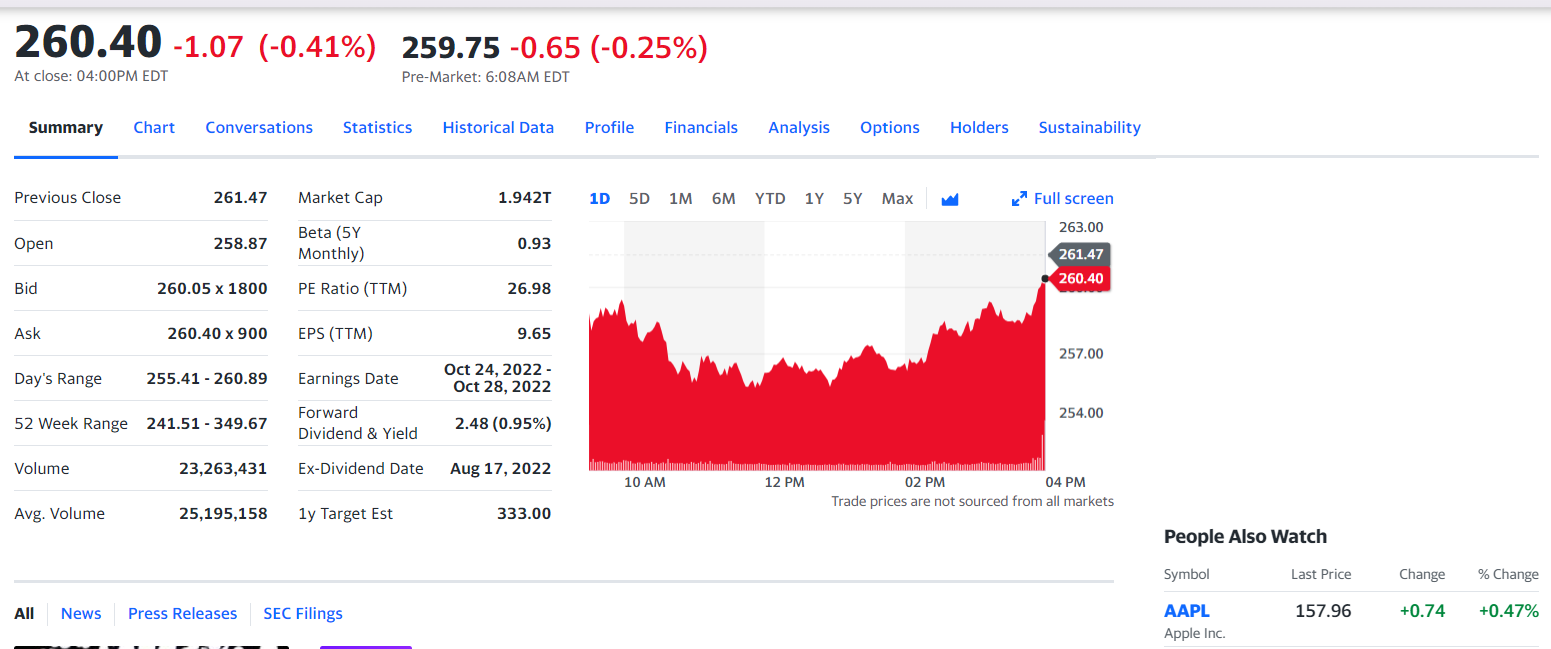

# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# Load Dataset

In [2]:
df=pd.read_csv('MSFT.csv')

In [3]:
df.head()

,Date,Open,High,Low,Close,Adj_Close,Volume
0,1/3/2017,62.790001,62.840000,62.130001,62.580002,57.807823,20694100
1,1/4/2017,62.480000,62.750000,62.119999,62.299999,57.549179,21340000
2,1/5/2017,62.189999,62.660000,62.029999,62.299999,57.549179,24876000
3,1/6/2017,62.299999,63.150002,62.040001,62.840000,58.047993,19922900
4,1/9/2017,62.759998,63.080002,62.540001,62.639999,57.863243,20382700


In [4]:
df.tail()

,Date,Open,High,Low,Close,Adj_Close,Volume
1421,8/25/2022,277.329987,279.019989,274.519989,278.850006,278.850006,16583400
1422,8/26/2022,279.079987,280.339996,267.980011,268.089996,268.089996,27532500
1423,8/29/2022,265.850006,267.399994,263.850006,265.230011,265.230011,20338500
1424,8/30/2022,266.670013,267.049988,260.660004,262.970001,262.970001,22767100
1425,8/31/2022,265.390015,267.109985,261.329987,261.470001,261.470001,24728900


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1426 entries, 0 to 1425
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       1426 non-null   object 
 1   Open       1426 non-null   float64
 2   High       1426 non-null   float64
 3   Low        1426 non-null   float64
 4   Close      1426 non-null   float64
 5   Adj_Close  1426 non-null   float64
 6   Volume     1426 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 78.1+ KB


In [6]:
df.describe()

,Open,High,Low,Close,Adj_Close,Volume
count,1426.000000,1426.000000,1426.000000,1426.000000,1426.000000,1.426000e+03
mean,169.561353,171.243268,167.753464,169.588822,165.923293,2.890647e+07
std,82.510456,83.402749,81.533050,82.509972,83.539829,1.262903e+07
min,62.189999,62.660000,61.950001,62.299999,57.549179,7.425600e+06
25%,98.414999,99.912503,97.302502,98.444999,93.971957,2.075820e+07
50%,142.135002,144.700005,139.805001,141.455002,137.402313,2.568230e+07
75%,243.832501,245.525005,241.487496,243.752502,240.720517,3.318965e+07
max,344.619995,349.670013,342.200012,343.109985,340.882782,1.112421e+08


# Compute Mean, STD, Min and Max Values

In [7]:
df.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj_Close', 'Volume'], dtype='object')

In [8]:
df.shape

(1426, 7)

In [9]:
df.isnull().any()

Date         False
Open         False
High         False
Low          False
Close        False
Adj_Close    False
Volume       False
dtype: bool

In [10]:
df.isnull()

,Date,Open,High,Low,Close,Adj_Close,Volume
0,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...
1421,False,False,False,False,False,False,False
1422,False,False,False,False,False,False,False
1423,False,False,False,False,False,False,False
1424,False,False,False,False,False,False,False


# Visualize the overall trend of the Dataset

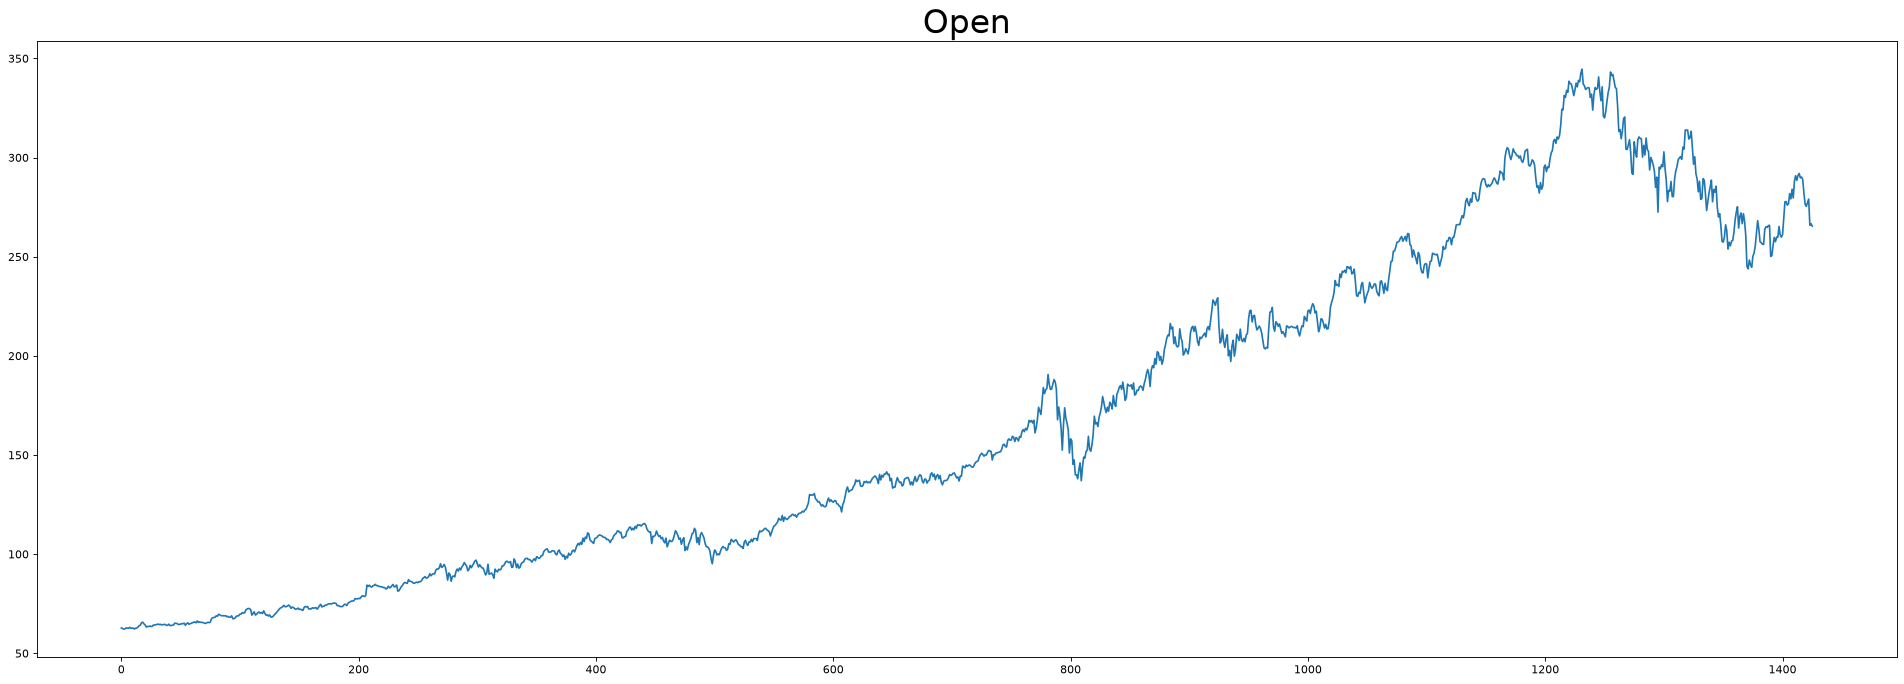

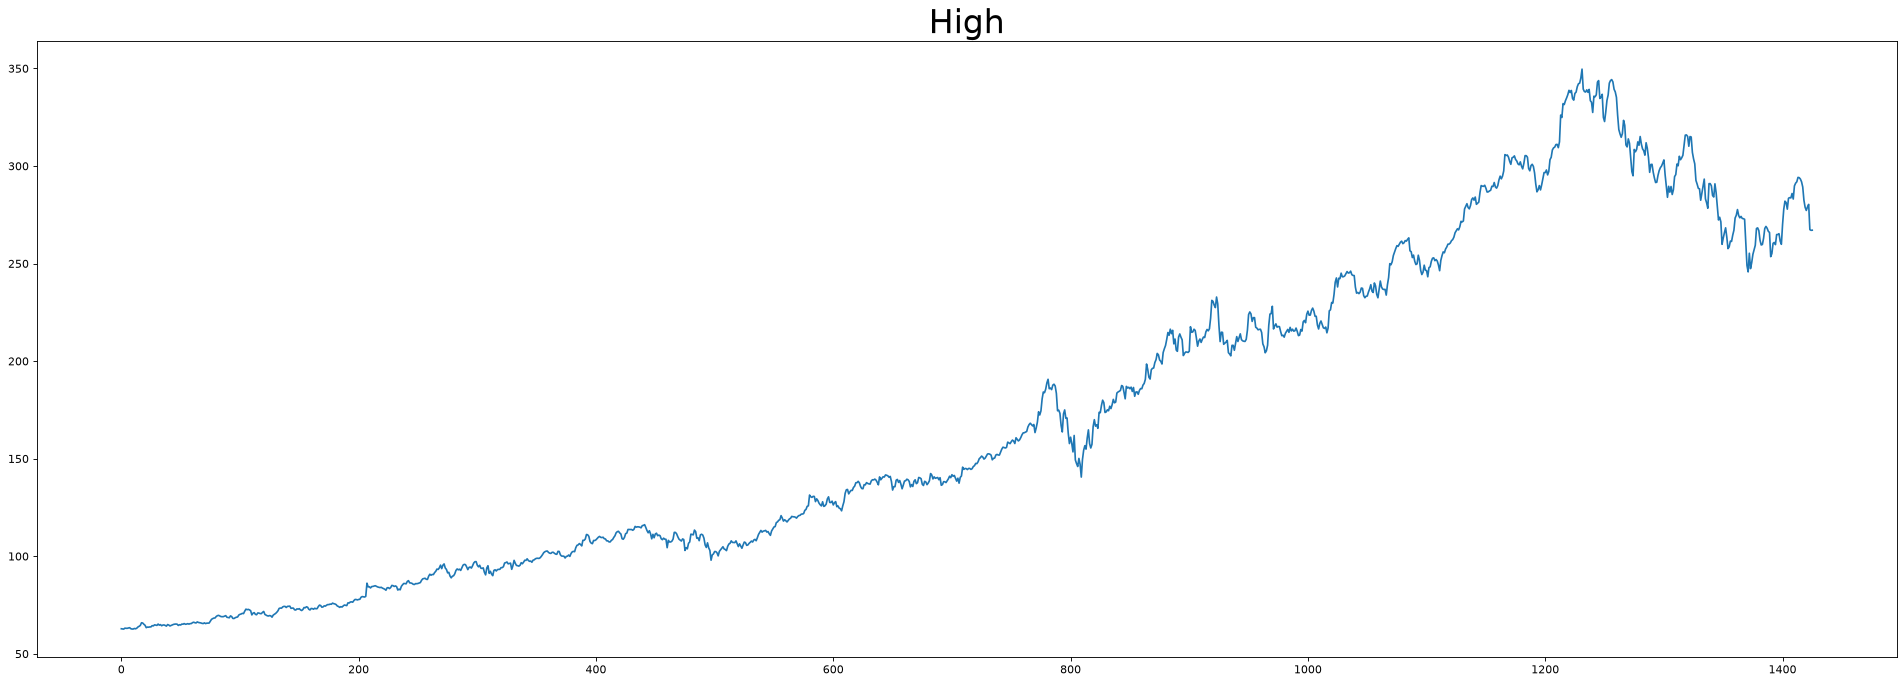

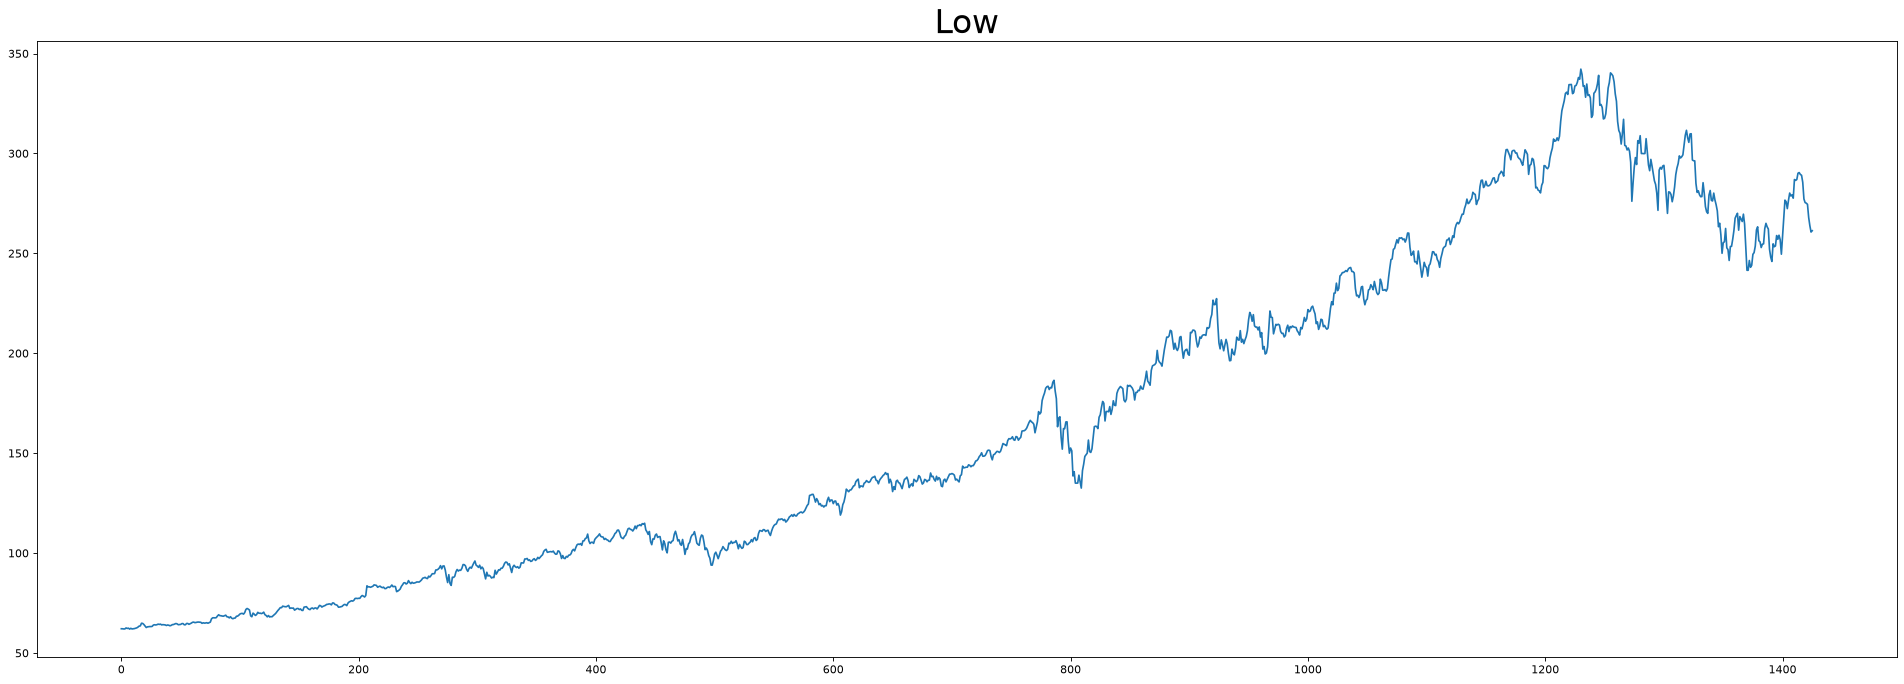

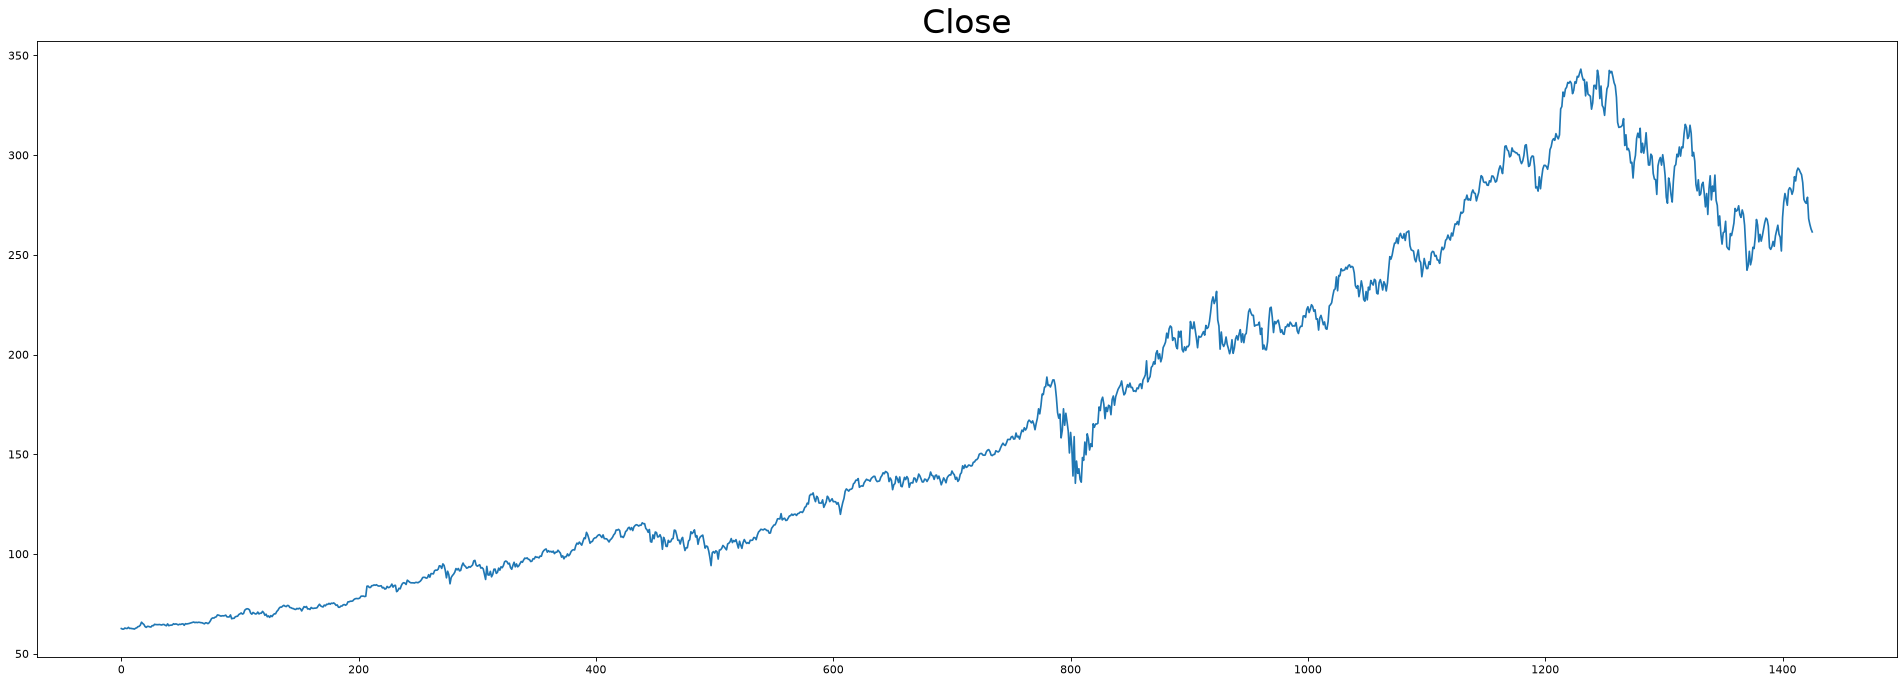

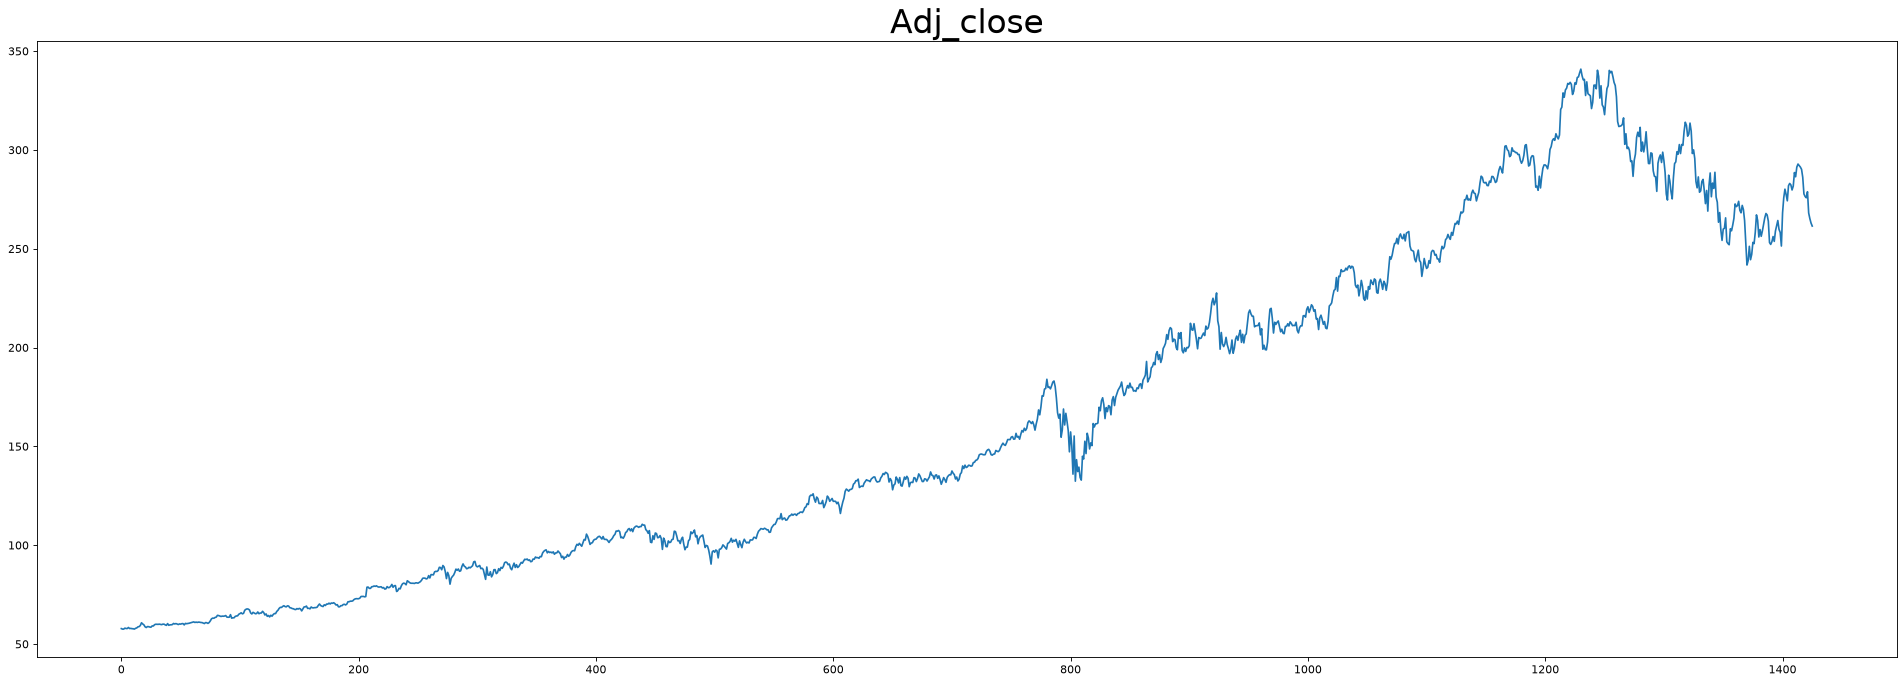

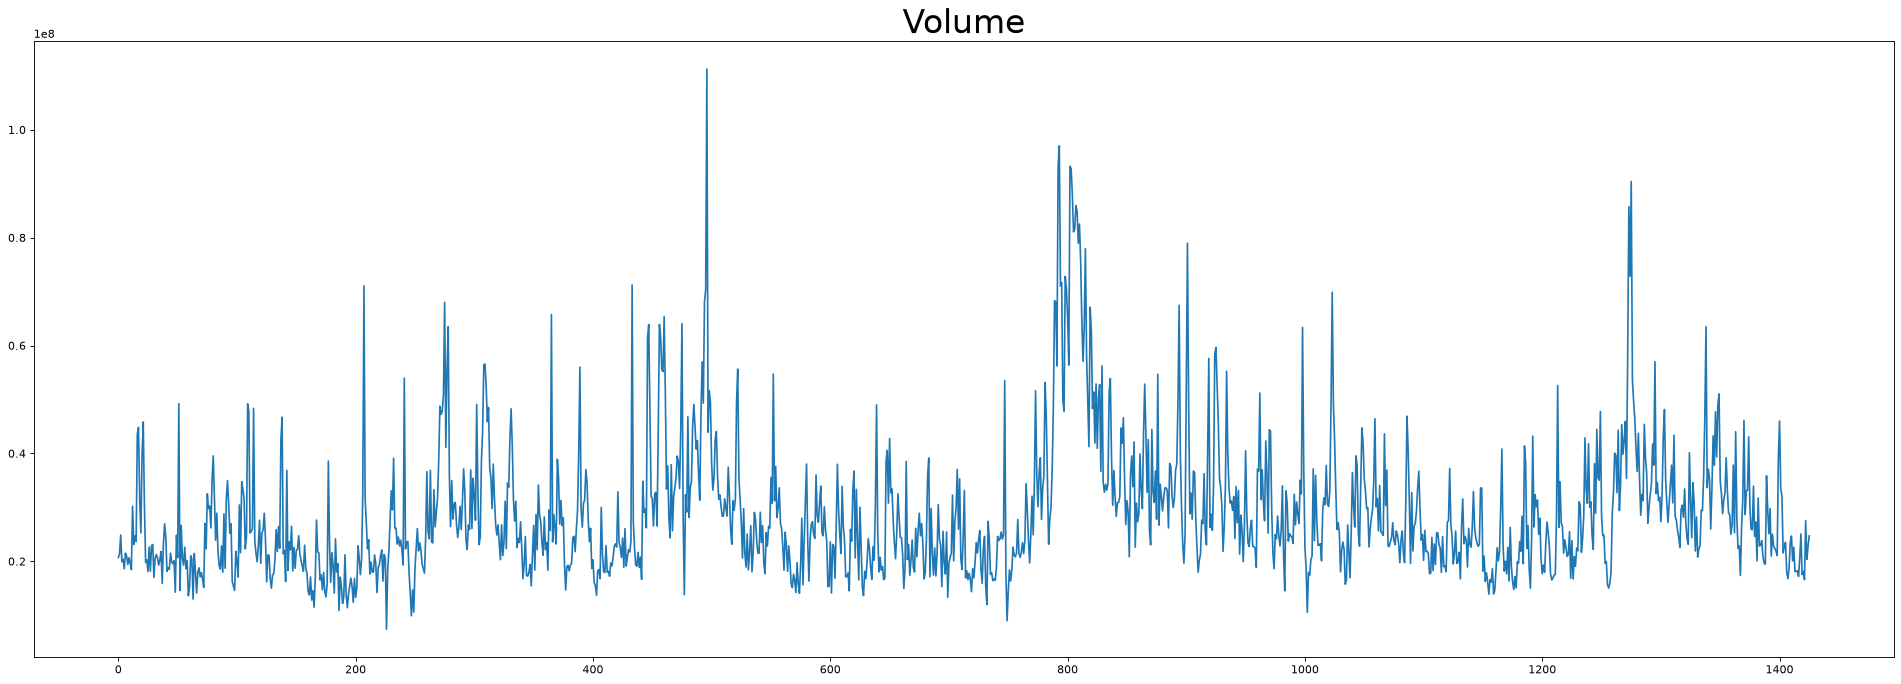

In [11]:
plt.figure(num=None, figsize=(30,10), dpi=80, facecolor='w',edgecolor='k')
plt.title('Open', fontsize=30)
plt.plot(df.Open)

plt.figure(num=None, figsize=(30,10), dpi=80, facecolor='w',edgecolor='k')
plt.title('High', fontsize=30)
plt.plot(df.High)

plt.figure(num=None, figsize=(30,10), dpi=80, facecolor='w',edgecolor='k')
plt.title('Low', fontsize=30)
plt.plot(df.Low)

plt.figure(num=None, figsize=(30,10), dpi=80, facecolor='w',edgecolor='k')
plt.title('Close', fontsize=30)
plt.plot(df.Close)

plt.figure(num=None, figsize=(30,10), dpi=80, facecolor='w',edgecolor='k')
plt.title('Adj_close', fontsize=30)
plt.plot(df.Adj_Close)

plt.figure(num=None, figsize=(30,10), dpi=80, facecolor='w',edgecolor='k')
plt.title('Volume', fontsize=30)
plt.plot(df.Volume)



# Line Plot

In [12]:
df.set_index('Date',inplace=True)
df.head()

,Open,High,Low,Close,Adj_Close,Volume
Date,,,,,,
1/3/2017,62.790001,62.840000,62.130001,62.580002,57.807823,20694100
1/4/2017,62.480000,62.750000,62.119999,62.299999,57.549179,21340000
1/5/2017,62.189999,62.660000,62.029999,62.299999,57.549179,24876000
1/6/2017,62.299999,63.150002,62.040001,62.840000,58.047993,19922900
1/9/2017,62.759998,63.080002,62.540001,62.639999,57.863243,20382700


In [13]:
df

,Open,High,Low,Close,Adj_Close,Volume
Date,,,,,,
1/3/2017,62.790001,62.840000,62.130001,62.580002,57.807823,20694100
1/4/2017,62.480000,62.750000,62.119999,62.299999,57.549179,21340000
1/5/2017,62.189999,62.660000,62.029999,62.299999,57.549179,24876000
1/6/2017,62.299999,63.150002,62.040001,62.840000,58.047993,19922900
1/9/2017,62.759998,63.080002,62.540001,62.639999,57.863243,20382700
...,...,...,...,...,...,...
8/25/2022,277.329987,279.019989,274.519989,278.850006,278.850006,16583400
8/26/2022,279.079987,280.339996,267.980011,268.089996,268.089996,27532500
8/29/2022,265.850006,267.399994,263.850006,265.230011,265.230011,20338500


In [14]:
df.index


Index(['1/3/2017', '1/4/2017', '1/5/2017', '1/6/2017', '1/9/2017', '1/10/2017',
       '1/11/2017', '1/12/2017', '1/13/2017', '1/17/2017',
       ...
       '8/18/2022', '8/19/2022', '8/22/2022', '8/23/2022', '8/24/2022',
       '8/25/2022', '8/26/2022', '8/29/2022', '8/30/2022', '8/31/2022'],
      dtype='object', name='Date', length=1426)

In [15]:
df

,Open,High,Low,Close,Adj_Close,Volume
Date,,,,,,
1/3/2017,62.790001,62.840000,62.130001,62.580002,57.807823,20694100
1/4/2017,62.480000,62.750000,62.119999,62.299999,57.549179,21340000
1/5/2017,62.189999,62.660000,62.029999,62.299999,57.549179,24876000
1/6/2017,62.299999,63.150002,62.040001,62.840000,58.047993,19922900
1/9/2017,62.759998,63.080002,62.540001,62.639999,57.863243,20382700
...,...,...,...,...,...,...
8/25/2022,277.329987,279.019989,274.519989,278.850006,278.850006,16583400
8/26/2022,279.079987,280.339996,267.980011,268.089996,268.089996,27532500
8/29/2022,265.850006,267.399994,263.850006,265.230011,265.230011,20338500


In [16]:
df.index = pd.to_datetime(df.index)

## ¿Cuántas diferencias entre tiempos consecutivos hay en la base df?

In [17]:
df.index.to_series().diff().value_counts()

Date
1 days    1117
3 days     257
4 days      38
2 days      13
Name: count, dtype: int64

In [18]:
# 1. Reindexar a frecuencia diaria ('D')
df_reindexed = df.asfreq('D')

# 2. Rellenar interpolando linealmente
df_final = df_reindexed.ffill()

print(df_final)

                  Open        High         Low       Close   Adj_Close  \
Date                                                                     
2017-01-03   62.790001   62.840000   62.130001   62.580002   57.807823   
2017-01-04   62.480000   62.750000   62.119999   62.299999   57.549179   
2017-01-05   62.189999   62.660000   62.029999   62.299999   57.549179   
2017-01-06   62.299999   63.150002   62.040001   62.840000   58.047993   
2017-01-07   62.299999   63.150002   62.040001   62.840000   58.047993   
...                ...         ...         ...         ...         ...   
2022-08-27  279.079987  280.339996  267.980011  268.089996  268.089996   
2022-08-28  279.079987  280.339996  267.980011  268.089996  268.089996   
2022-08-29  265.850006  267.399994  263.850006  265.230011  265.230011   
2022-08-30  266.670013  267.049988  260.660004  262.970001  262.970001   
2022-08-31  265.390015  267.109985  261.329987  261.470001  261.470001   

                Volume  
Date        

In [19]:
df_final

,Open,High,Low,Close,Adj_Close,Volume
Date,,,,,,
2017-01-03,62.790001,62.840000,62.130001,62.580002,57.807823,20694100.0
2017-01-04,62.480000,62.750000,62.119999,62.299999,57.549179,21340000.0
2017-01-05,62.189999,62.660000,62.029999,62.299999,57.549179,24876000.0
2017-01-06,62.299999,63.150002,62.040001,62.840000,58.047993,19922900.0
2017-01-07,62.299999,63.150002,62.040001,62.840000,58.047993,19922900.0
...,...,...,...,...,...,...
2022-08-27,279.079987,280.339996,267.980011,268.089996,268.089996,27532500.0
2022-08-28,279.079987,280.339996,267.980011,268.089996,268.089996,27532500.0
2022-08-29,265.850006,267.399994,263.850006,265.230011,265.230011,20338500.0


In [20]:
df = df_final

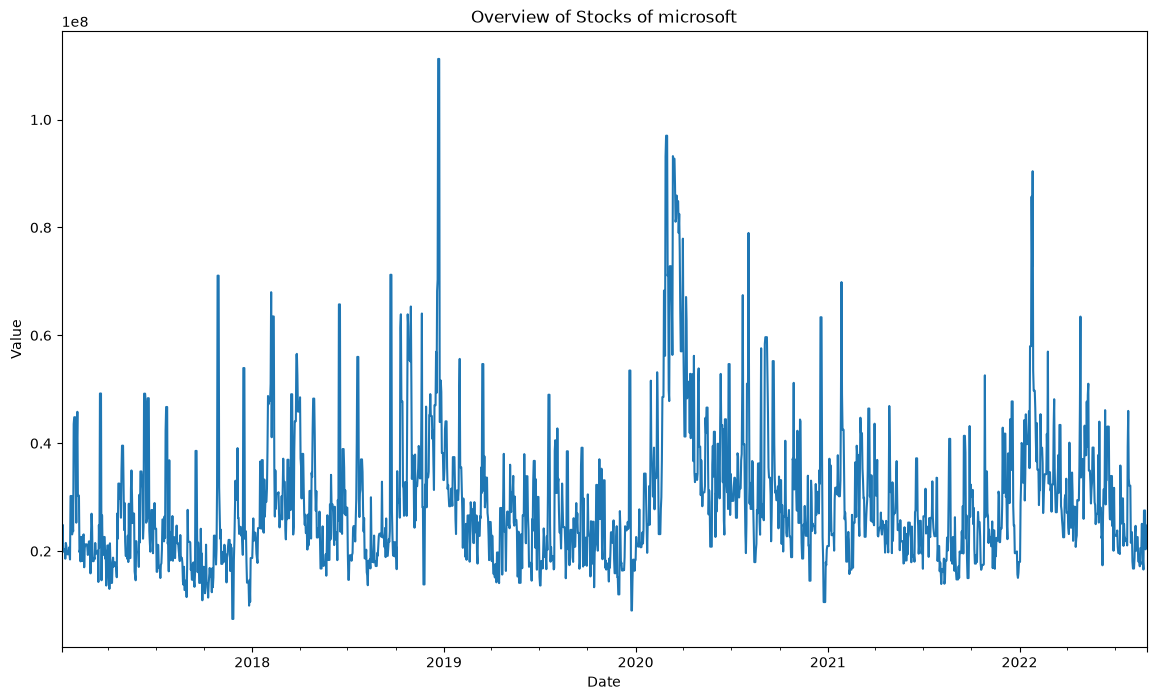

In [21]:
df['Volume'].plot(kind='line',figsize=(14,8))

plt.title('Overview of Stocks of microsoft')
plt.ylabel('Value')
plt.xlabel('Date')
plt.show()

# Area Plot

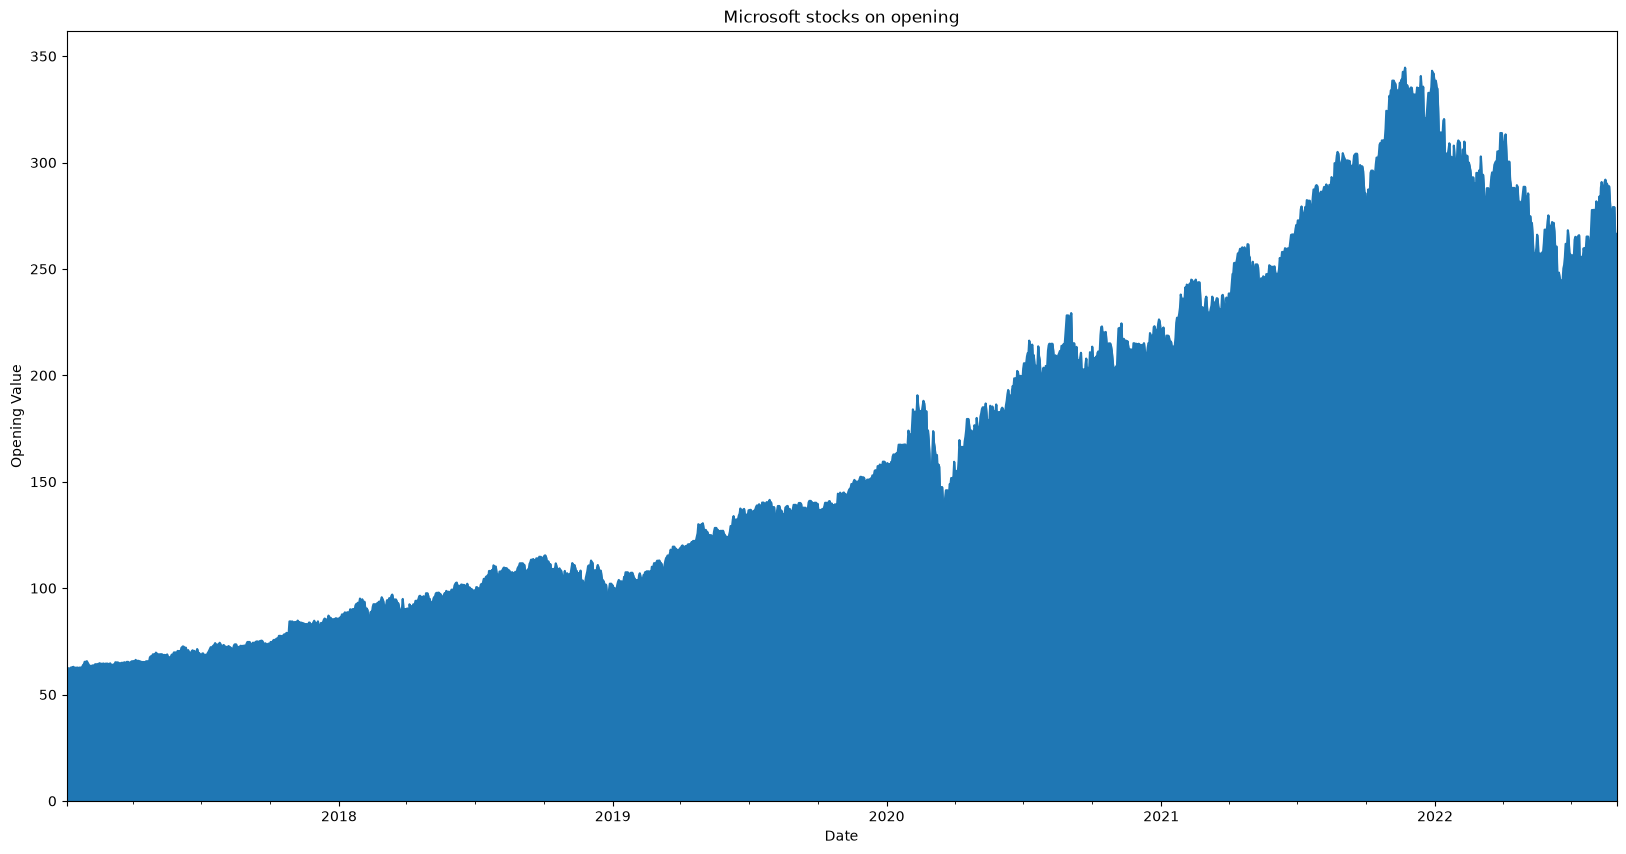

In [22]:
df['Open'].plot(kind='area',stacked=True,figsize=(20,10))

plt.title('Microsoft stocks on opening')
plt.ylabel('Opening Value')
plt.xlabel('Date')

plt.show()

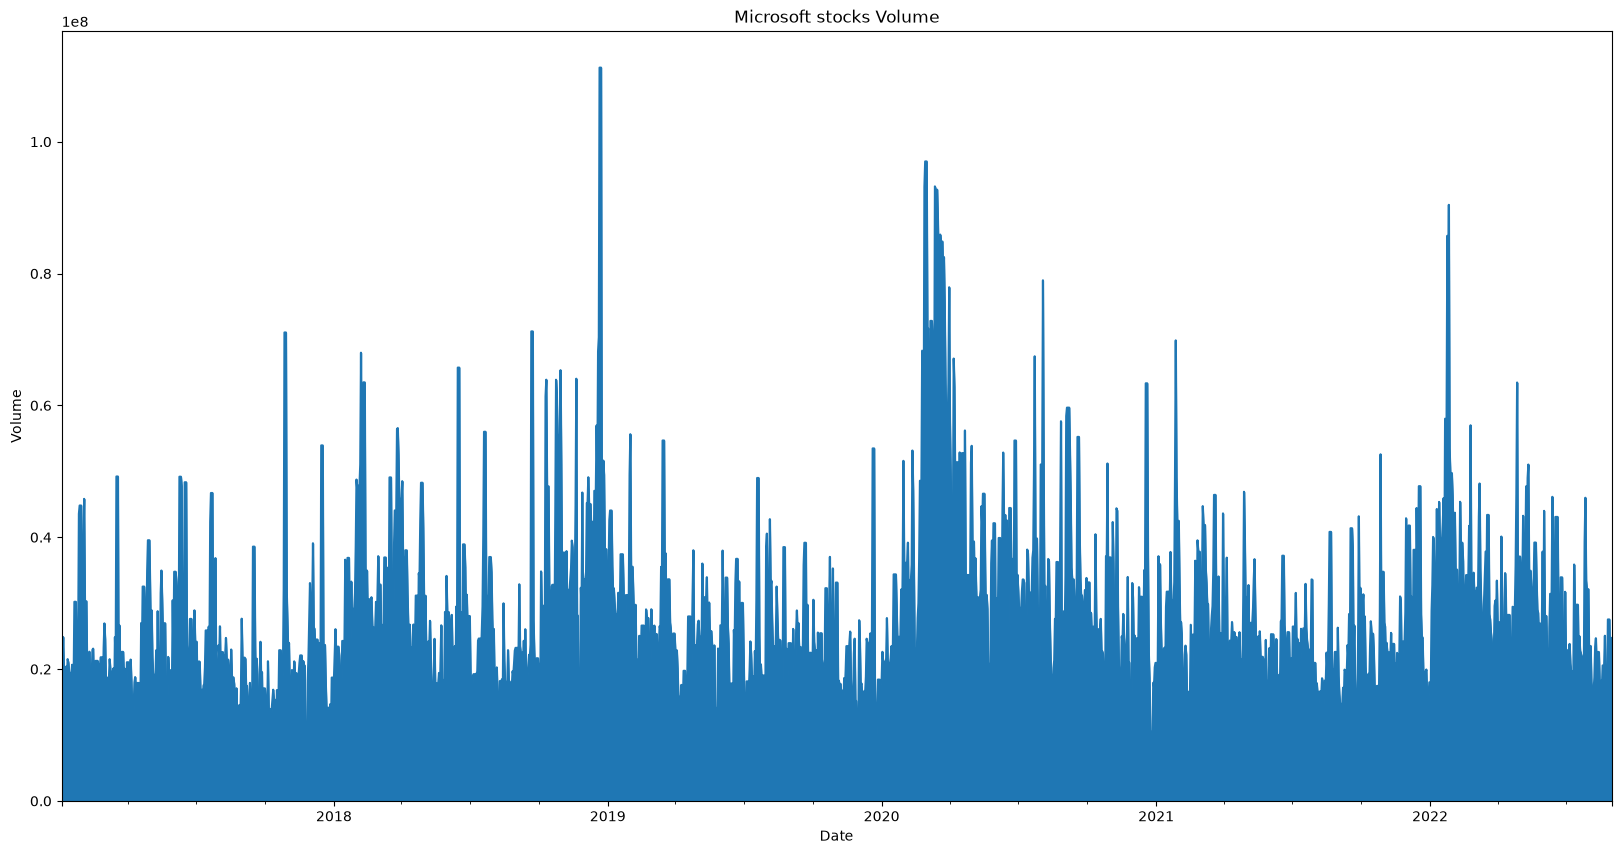

In [23]:
df['Volume'].plot(kind='area',stacked=True,figsize=(20,10))

plt.title('Microsoft stocks Volume')
plt.ylabel('Volume')
plt.xlabel('Date')

plt.show()

# Visualize Correlation, STD and Mean

In [24]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

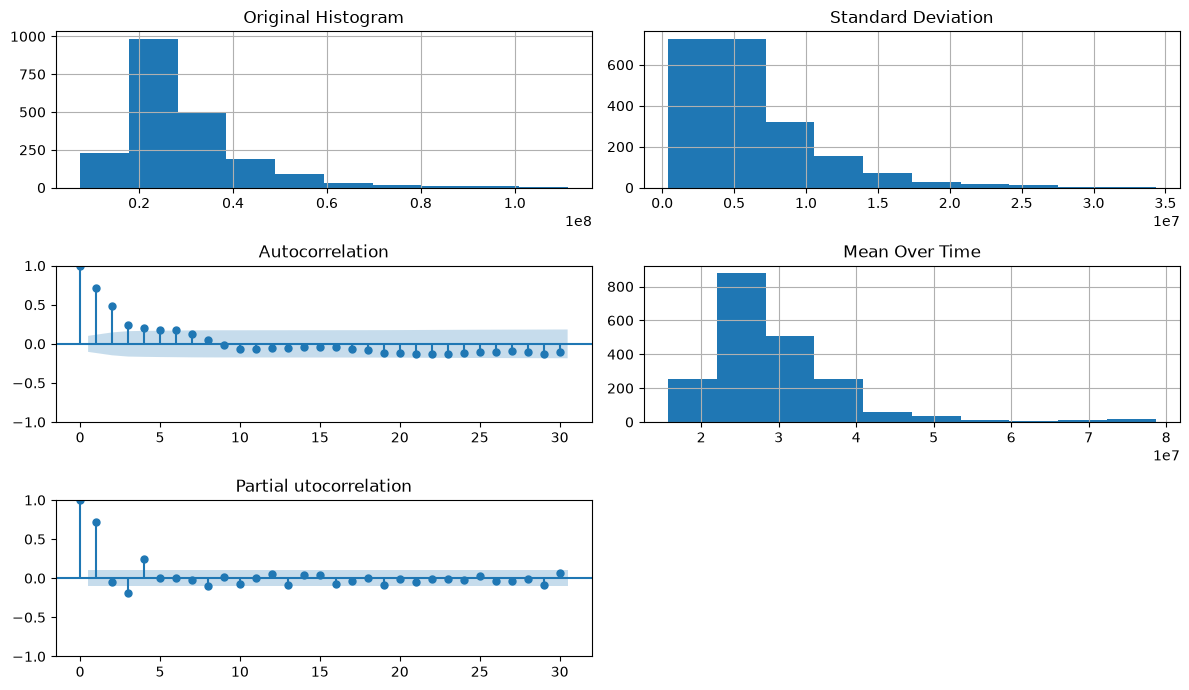

In [25]:
fig=plt.figure(figsize=(12,7))
layout=(3,2)
hist_ax=plt.subplot2grid(layout,(0,0))
ac_ax=plt.subplot2grid(layout,(1,0))
hist_std_ax= plt.subplot2grid(layout,(0,1))
mean_ax=plt.subplot2grid(layout,(1,1))
pac_ax=plt.subplot2grid(layout,(2,0))


df.Volume.hist(ax=hist_ax)
hist_ax.set_title("Original Histogram")

series= df.Volume[:365]

plot_acf(series, lags=30, ax=ac_ax)
ac_ax.set_title("Autocorrelation")

plot_pacf(series, lags=30, ax=pac_ax)
pac_ax.set_title("Partial utocorrelation")

mm= df.Volume.rolling(7).std()
mm.hist(ax=hist_std_ax)
hist_std_ax.set_title("Standard Deviation")

mm= df.Volume.rolling(30).mean()
mm.hist(ax=mean_ax)
mean_ax.set_title("Mean Over Time")

plt.tight_layout()


# Check Stationarity

In [26]:
from statsmodels.tsa.stattools import adfuller

In [27]:
X=df.Volume.values
result=adfuller(X)

In [28]:
print('ADF Statistics:%f'%result[0])
print('p-value:%f'%result[1])

print('Critical Values')
for key, value in result[4].items():
    print('\t%s: %.3f'%(key,value))

ADF Statistics:-6.661315
p-value:0.000000
Critical Values
	1%: -3.434
	5%: -2.863
	10%: -2.568


## Se muestra que la demanda es estacionaria

# 1. Volume Forecasting using LSTM Model

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2067 entries, 2017-01-03 to 2022-08-31
Freq: D
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Open       2067 non-null   float64
 1   High       2067 non-null   float64
 2   Low        2067 non-null   float64
 3   Close      2067 non-null   float64
 4   Adj_Close  2067 non-null   float64
 5   Volume     2067 non-null   float64
dtypes: float64(6)
memory usage: 113.0 KB


In [30]:
#train_dates=pd.to_datetime(df['Date'])
#train_dates

In [31]:
df.reset_index(inplace=True)

In [32]:
df

,Date,Open,High,Low,Close,Adj_Close,Volume
0,2017-01-03,62.790001,62.840000,62.130001,62.580002,57.807823,20694100.0
1,2017-01-04,62.480000,62.750000,62.119999,62.299999,57.549179,21340000.0
2,2017-01-05,62.189999,62.660000,62.029999,62.299999,57.549179,24876000.0
3,2017-01-06,62.299999,63.150002,62.040001,62.840000,58.047993,19922900.0
4,2017-01-07,62.299999,63.150002,62.040001,62.840000,58.047993,19922900.0
...,...,...,...,...,...,...,...
2062,2022-08-27,279.079987,280.339996,267.980011,268.089996,268.089996,27532500.0
2063,2022-08-28,279.079987,280.339996,267.980011,268.089996,268.089996,27532500.0
2064,2022-08-29,265.850006,267.399994,263.850006,265.230011,265.230011,20338500.0
2065,2022-08-30,266.670013,267.049988,260.660004,262.970001,262.970001,22767100.0


In [33]:
train_dates=pd.to_datetime(df['Date'])
train_dates

0      2017-01-03
1      2017-01-04
2      2017-01-05
3      2017-01-06
4      2017-01-07
          ...    
2062   2022-08-27
2063   2022-08-28
2064   2022-08-29
2065   2022-08-30
2066   2022-08-31
Name: Date, Length: 2067, dtype: datetime64[ns]

In [34]:
cols=list(df)[6:7]
cols

['Volume']

In [35]:
df_for_training=df[cols].astype(float)
df_for_training

,Volume
0,20694100.0
1,21340000.0
2,24876000.0
3,19922900.0
4,19922900.0
...,...
2062,27532500.0
2063,27532500.0
2064,20338500.0
2065,22767100.0


<Axes: >

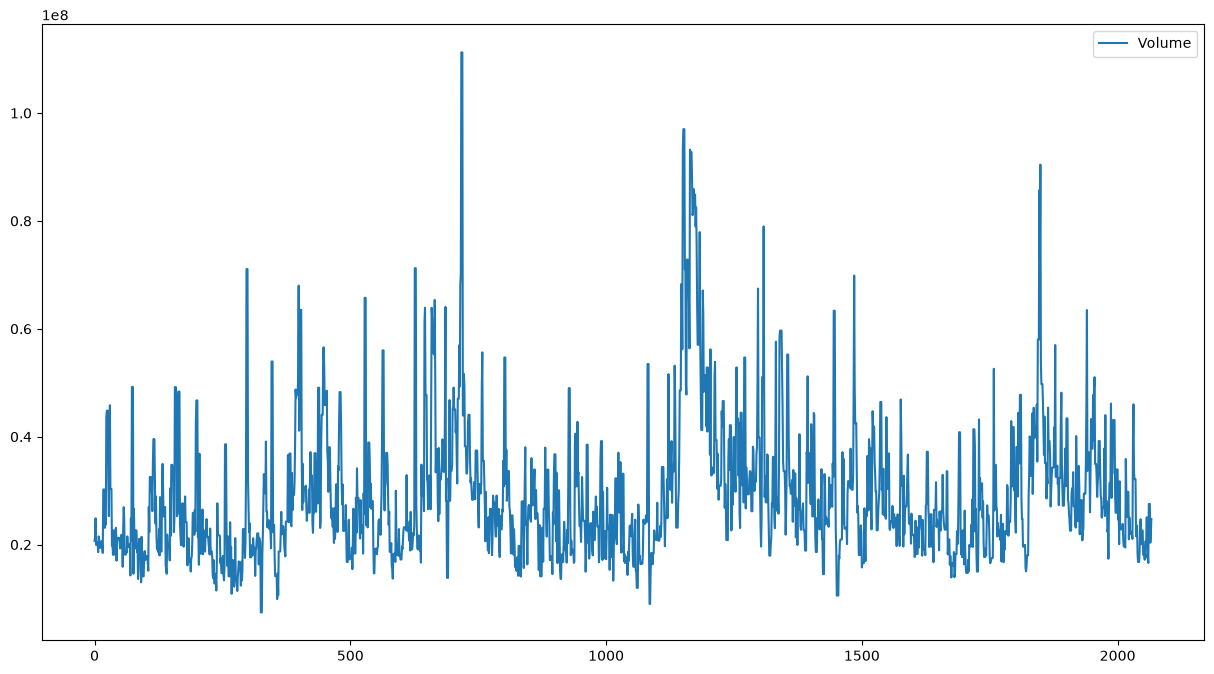

In [36]:
df_for_plot=df_for_training
df_for_plot.plot.line(figsize=(15,8))

<Axes: >

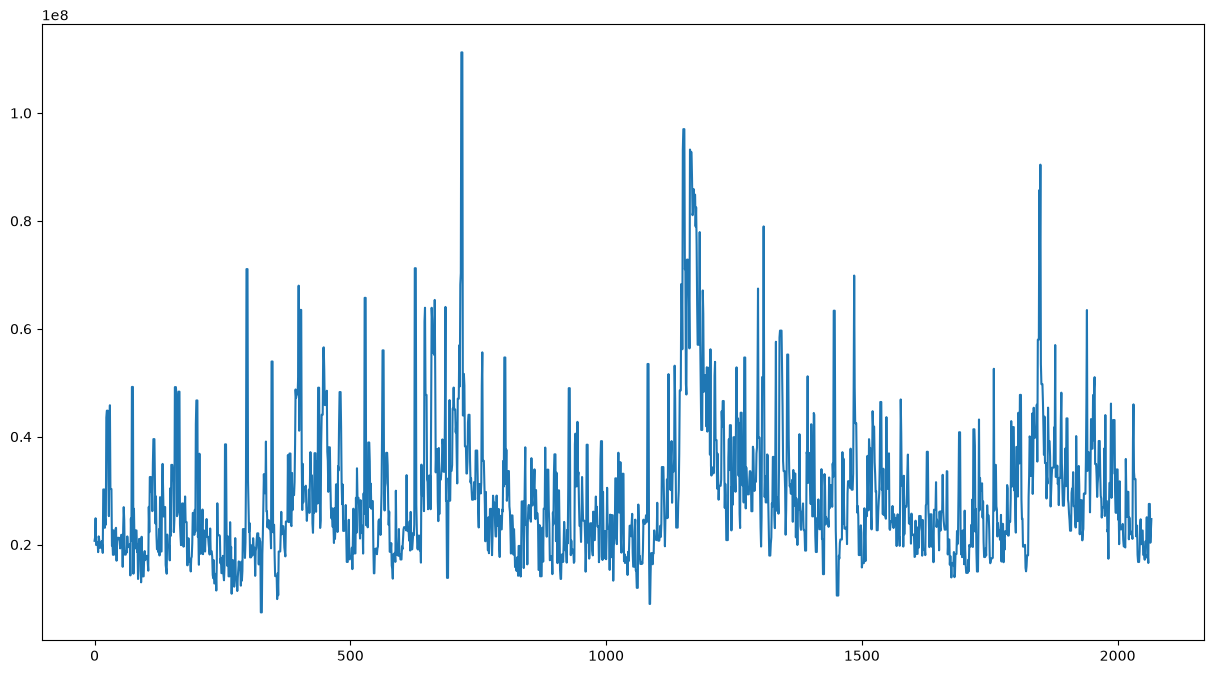

In [37]:
df['Volume'].plot(figsize=(15,8))

In [38]:
from sklearn.preprocessing import StandardScaler

In [39]:
scaler=StandardScaler()

In [40]:
scaler=scaler.fit(df_for_training)
df_for_training_scaled=scaler.transform(df_for_training)

In [41]:
df_for_training_scaled

array([[-0.65942561],
       [-0.61011439],
       [-0.34015856],
       ...,
       [-0.68657388],
       [-0.50116248],
       [-0.35138891]], shape=(2067, 1))

In [42]:
df_for_training.shape[1]

1

In [43]:
len(df_for_training_scaled)

2067

In [44]:
trainX=[]
trainY=[]

n_future=1
n_past=25
for i in range(n_past, len(df_for_training_scaled) - n_future + 1):
    trainX.append(df_for_training_scaled[i-n_past:i,0:df_for_training.shape[1]])
    trainY.append(df_for_training_scaled[i+n_future-1:i+n_future,0])

trainX,trainY=np.array(trainX), np.array(trainY)

print('trainX shape==={}.'.format(trainX.shape))
print('trainY shape==={}.'.format(trainY.shape))

trainX shape===(2042, 25, 1).
trainY shape===(2042, 1).


In [45]:
from keras.models import Sequential

In [46]:
from tensorflow.keras.layers import LSTM, Dense, Activation, Dropout, Bidirectional, BatchNormalization, Embedding

In [47]:
from keras.models import Sequential
from keras.layers import Bidirectional, LSTM, Dropout, Dense, Input

model = Sequential()

model.add(Input(shape=(trainX.shape[1], trainX.shape[2])))

model.add(Bidirectional(LSTM(32, activation='relu', return_sequences=False)))
model.add(Dropout(0.2))

model.add(Dense(1))   # <-- single output
model.compile(optimizer='adam', loss='mse')

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)        │ (None, 64)                  │           8,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 8,769 (34.25 KB)

 Trainable params: 8,769 (34.25 KB)

 Non-trainable params: 0 (0.00 B)

In [48]:
history=model.fit(trainX,trainY,epochs=62,batch_size=16,validation_split=0.1,verbose=1)

Epoch 1/62
115/115 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 2.0976 - val_loss: 0.2902
Epoch 2/62
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.8214 - val_loss: 0.2776
Epoch 3/62
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.6521 - val_loss: 0.2617
Epoch 4/62
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.6078 - val_loss: 0.2503
Epoch 5/62
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.5770 - val_loss: 0.2428
Epoch 6/62
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.5475 - val_loss: 0.2427
Epoch 7/62
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.5012 - val_loss: 0.2471
Epoch 8/62
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4754 - val_loss: 0.2836
Epoch 9/62
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4462 - val_loss: 0.2360
Epoch 10/62
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4303 - val_loss: 0.2242
Epoch 11/62
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4429 - val_loss: 0.2233
Epoch 12/62
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/ste

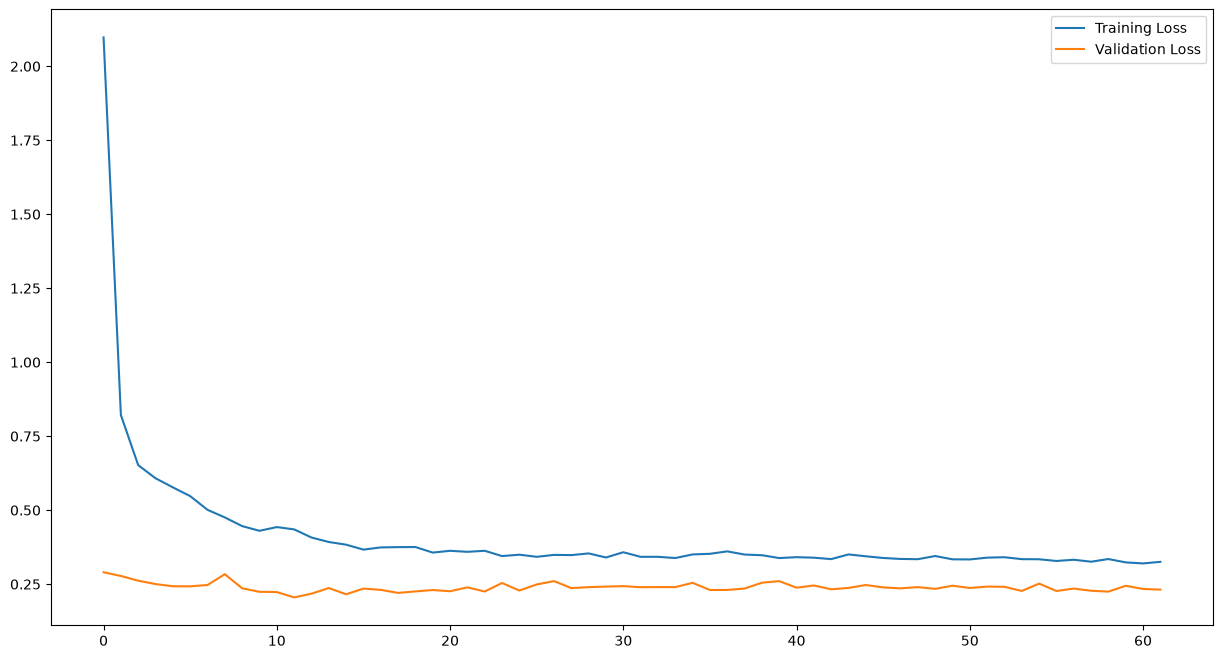

In [49]:
plt.figure(figsize=(15, 8))  
plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()

## Forecasting with BILSTM

In [50]:
from pandas.tseries.holiday import USFederalHolidayCalendar

In [51]:
from pandas.tseries.offsets import CustomBusinessDay

In [52]:
us_bd=CustomBusinessDay(calendar=USFederalHolidayCalendar())

In [53]:
n_past=10
n_days_for_prediction=100


In [54]:
predict_period_dates=pd.date_range(list(train_dates)[-n_past],periods=n_days_for_prediction,freq=us_bd).tolist()

In [55]:
predict_period_dates

[Timestamp('2022-08-22 00:00:00'),
 Timestamp('2022-08-23 00:00:00'),
 Timestamp('2022-08-24 00:00:00'),
 Timestamp('2022-08-25 00:00:00'),
 Timestamp('2022-08-26 00:00:00'),
 Timestamp('2022-08-29 00:00:00'),
 Timestamp('2022-08-30 00:00:00'),
 Timestamp('2022-08-31 00:00:00'),
 Timestamp('2022-09-01 00:00:00'),
 Timestamp('2022-09-02 00:00:00'),
 Timestamp('2022-09-06 00:00:00'),
 Timestamp('2022-09-07 00:00:00'),
 Timestamp('2022-09-08 00:00:00'),
 Timestamp('2022-09-09 00:00:00'),
 Timestamp('2022-09-12 00:00:00'),
 Timestamp('2022-09-13 00:00:00'),
 Timestamp('2022-09-14 00:00:00'),
 Timestamp('2022-09-15 00:00:00'),
 Timestamp('2022-09-16 00:00:00'),
 Timestamp('2022-09-19 00:00:00'),
 Timestamp('2022-09-20 00:00:00'),
 Timestamp('2022-09-21 00:00:00'),
 Timestamp('2022-09-22 00:00:00'),
 Timestamp('2022-09-23 00:00:00'),
 Timestamp('2022-09-26 00:00:00'),
 Timestamp('2022-09-27 00:00:00'),
 Timestamp('2022-09-28 00:00:00'),
 Timestamp('2022-09-29 00:00:00'),
 Timestamp('2022-09-

In [56]:
prediction=model.predict(trainX[-n_days_for_prediction:])

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step


In [57]:
prediction[99]

array([-0.43534017], dtype=float32)

In [58]:
prediction_copies=np.repeat(prediction,df_for_training.shape[1],axis=-1)

prediction_copies.shape

(100, 1)

In [59]:
prediction_copies

array([[ 5.5776763e-01],
       [ 1.8315314e-01],
       [ 1.5187289e-01],
       [-1.9325534e-01],
       [-1.2089062e-01],
       [-7.6153785e-02],
       [-9.5281377e-02],
       [-9.8837972e-02],
       [ 7.7098662e-01],
       [-9.2695609e-02],
       [ 1.0233202e+00],
       [ 3.8646124e-02],
       [-3.6336720e-02],
       [-4.5685679e-02],
       [-2.7670753e-01],
       [-3.2933092e-01],
       [-5.8196473e-01],
       [-2.7819395e-01],
       [ 3.8351245e-02],
       [ 8.3844677e-02],
       [ 1.2742952e-01],
       [ 1.0570546e+00],
       [ 1.4488779e-01],
       [ 2.3073232e-01],
       [ 2.5961345e-01],
       [ 9.8833495e-01],
       [ 9.7265524e-01],
       [ 9.3780571e-01],
       [ 8.8870490e-01],
       [ 2.1426532e-01],
       [-2.3031712e-02],
       [-8.6667687e-02],
       [ 4.3731964e-01],
       [ 5.2878797e-01],
       [ 5.0328839e-01],
       [-6.5227062e-02],
       [ 4.7308281e-02],
       [-4.7871536e-01],
       [ 3.1874752e-01],
       [-3.3072630e-01],


In [60]:
df_for_training.shape[1]

1

In [61]:
df_for_training

,Volume
0,20694100.0
1,21340000.0
2,24876000.0
3,19922900.0
4,19922900.0
...,...
2062,27532500.0
2063,27532500.0
2064,20338500.0
2065,22767100.0


In [62]:
(trainX.shape[1], trainX.shape[2])

(25, 1)

In [63]:
prediction

array([[ 5.5776763e-01],
       [ 1.8315314e-01],
       [ 1.5187289e-01],
       [-1.9325534e-01],
       [-1.2089062e-01],
       [-7.6153785e-02],
       [-9.5281377e-02],
       [-9.8837972e-02],
       [ 7.7098662e-01],
       [-9.2695609e-02],
       [ 1.0233202e+00],
       [ 3.8646124e-02],
       [-3.6336720e-02],
       [-4.5685679e-02],
       [-2.7670753e-01],
       [-3.2933092e-01],
       [-5.8196473e-01],
       [-2.7819395e-01],
       [ 3.8351245e-02],
       [ 8.3844677e-02],
       [ 1.2742952e-01],
       [ 1.0570546e+00],
       [ 1.4488779e-01],
       [ 2.3073232e-01],
       [ 2.5961345e-01],
       [ 9.8833495e-01],
       [ 9.7265524e-01],
       [ 9.3780571e-01],
       [ 8.8870490e-01],
       [ 2.1426532e-01],
       [-2.3031712e-02],
       [-8.6667687e-02],
       [ 4.3731964e-01],
       [ 5.2878797e-01],
       [ 5.0328839e-01],
       [-6.5227062e-02],
       [ 4.7308281e-02],
       [-4.7871536e-01],
       [ 3.1874752e-01],
       [-3.3072630e-01],


In [64]:
prediction[99]

array([-0.43534017], dtype=float32)

In [65]:
trainX[-n_days_for_prediction:]

array([[[ 0.59108978],
        [ 0.59108978],
        [ 0.59108978],
        ...,
        [ 0.75335338],
        [ 0.75335338],
        [ 0.2934589 ]],

       [[ 0.59108978],
        [ 0.59108978],
        [ 0.44429366],
        ...,
        [ 0.75335338],
        [ 0.2934589 ],
        [-0.02196035]],

       [[ 0.59108978],
        [ 0.44429366],
        [-0.2559806 ],
        ...,
        [ 0.2934589 ],
        [-0.02196035],
        [-0.05982746]],

       ...,

       [[-0.85757135],
        [-0.95917124],
        [-0.95917124],
        ...,
        [-0.13734814],
        [-0.13734814],
        [-0.13734814]],

       [[-0.95917124],
        [-0.95917124],
        [-0.95917124],
        ...,
        [-0.13734814],
        [-0.13734814],
        [-0.68657388]],

       [[-0.95917124],
        [-0.95917124],
        [-0.80867239],
        ...,
        [-0.13734814],
        [-0.68657388],
        [-0.50116248]]], shape=(100, 25, 1))

In [66]:
prediction_copies

array([[ 5.5776763e-01],
       [ 1.8315314e-01],
       [ 1.5187289e-01],
       [-1.9325534e-01],
       [-1.2089062e-01],
       [-7.6153785e-02],
       [-9.5281377e-02],
       [-9.8837972e-02],
       [ 7.7098662e-01],
       [-9.2695609e-02],
       [ 1.0233202e+00],
       [ 3.8646124e-02],
       [-3.6336720e-02],
       [-4.5685679e-02],
       [-2.7670753e-01],
       [-3.2933092e-01],
       [-5.8196473e-01],
       [-2.7819395e-01],
       [ 3.8351245e-02],
       [ 8.3844677e-02],
       [ 1.2742952e-01],
       [ 1.0570546e+00],
       [ 1.4488779e-01],
       [ 2.3073232e-01],
       [ 2.5961345e-01],
       [ 9.8833495e-01],
       [ 9.7265524e-01],
       [ 9.3780571e-01],
       [ 8.8870490e-01],
       [ 2.1426532e-01],
       [-2.3031712e-02],
       [-8.6667687e-02],
       [ 4.3731964e-01],
       [ 5.2878797e-01],
       [ 5.0328839e-01],
       [-6.5227062e-02],
       [ 4.7308281e-02],
       [-4.7871536e-01],
       [ 3.1874752e-01],
       [-3.3072630e-01],


In [67]:
y_pred_future=scaler.inverse_transform(prediction_copies)[:,0]

In [68]:
forecast_dates=[]
for time_i in predict_period_dates:
    forecast_dates.append(time_i.date())
    
df_forecast=pd.DataFrame({'Date':np.array(forecast_dates), 'Volume':y_pred_future})
df_forecast['Date']=pd.to_datetime(df_forecast['Date'])

In [69]:
df_forecast.set_index('Date',inplace=True)

In [70]:
df.set_index('Date',inplace=True)

In [71]:
#df.set_index('Date',inplace=True)
df

,Open,High,Low,Close,Adj_Close,Volume
Date,,,,,,
2017-01-03,62.790001,62.840000,62.130001,62.580002,57.807823,20694100.0
2017-01-04,62.480000,62.750000,62.119999,62.299999,57.549179,21340000.0
2017-01-05,62.189999,62.660000,62.029999,62.299999,57.549179,24876000.0
2017-01-06,62.299999,63.150002,62.040001,62.840000,58.047993,19922900.0
2017-01-07,62.299999,63.150002,62.040001,62.840000,58.047993,19922900.0
...,...,...,...,...,...,...
2022-08-27,279.079987,280.339996,267.980011,268.089996,268.089996,27532500.0
2022-08-28,279.079987,280.339996,267.980011,268.089996,268.089996,27532500.0
2022-08-29,265.850006,267.399994,263.850006,265.230011,265.230011,20338500.0


In [72]:
df_forecast

,Volume
Date,
2022-08-22,36637432.0
2022-08-23,31730566.0
2022-08-24,31320844.0
2022-08-25,26800202.0
2022-08-26,27748068.0
...,...
2023-01-10,25444224.0
2023-01-11,29195530.0
2023-01-12,29341660.0


In [73]:
df_forecast.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 100 entries, 2022-08-22 to 2023-01-17
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Volume  100 non-null    float32
dtypes: float32(1)
memory usage: 1.2 KB


In [74]:
df_forecast.index

DatetimeIndex(['2022-08-22', '2022-08-23', '2022-08-24', '2022-08-25',
               '2022-08-26', '2022-08-29', '2022-08-30', '2022-08-31',
               '2022-09-01', '2022-09-02', '2022-09-06', '2022-09-07',
               '2022-09-08', '2022-09-09', '2022-09-12', '2022-09-13',
               '2022-09-14', '2022-09-15', '2022-09-16', '2022-09-19',
               '2022-09-20', '2022-09-21', '2022-09-22', '2022-09-23',
               '2022-09-26', '2022-09-27', '2022-09-28', '2022-09-29',
               '2022-09-30', '2022-10-03', '2022-10-04', '2022-10-05',
               '2022-10-06', '2022-10-07', '2022-10-11', '2022-10-12',
               '2022-10-13', '2022-10-14', '2022-10-17', '2022-10-18',
               '2022-10-19', '2022-10-20', '2022-10-21', '2022-10-24',
               '2022-10-25', '2022-10-26', '2022-10-27', '2022-10-28',
               '2022-10-31', '2022-11-01', '2022-11-02', '2022-11-03',
               '2022-11-04', '2022-11-07', '2022-11-08', '2022-11-09',
      

In [75]:
df_forecast.index = pd.date_range('2022-08-22', periods=len(df_forecast), freq=us_bd)
df_forecast.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 100 entries, 2022-08-22 to 2023-01-17
Freq: C
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Volume  100 non-null    float32
dtypes: float32(1)
memory usage: 1.2 KB


In [76]:
df_forecast.index

DatetimeIndex(['2022-08-22', '2022-08-23', '2022-08-24', '2022-08-25',
               '2022-08-26', '2022-08-29', '2022-08-30', '2022-08-31',
               '2022-09-01', '2022-09-02', '2022-09-06', '2022-09-07',
               '2022-09-08', '2022-09-09', '2022-09-12', '2022-09-13',
               '2022-09-14', '2022-09-15', '2022-09-16', '2022-09-19',
               '2022-09-20', '2022-09-21', '2022-09-22', '2022-09-23',
               '2022-09-26', '2022-09-27', '2022-09-28', '2022-09-29',
               '2022-09-30', '2022-10-03', '2022-10-04', '2022-10-05',
               '2022-10-06', '2022-10-07', '2022-10-11', '2022-10-12',
               '2022-10-13', '2022-10-14', '2022-10-17', '2022-10-18',
               '2022-10-19', '2022-10-20', '2022-10-21', '2022-10-24',
               '2022-10-25', '2022-10-26', '2022-10-27', '2022-10-28',
               '2022-10-31', '2022-11-01', '2022-11-02', '2022-11-03',
               '2022-11-04', '2022-11-07', '2022-11-08', '2022-11-09',
      

In [77]:
df.index 

DatetimeIndex(['2017-01-03', '2017-01-04', '2017-01-05', '2017-01-06',
               '2017-01-07', '2017-01-08', '2017-01-09', '2017-01-10',
               '2017-01-11', '2017-01-12',
               ...
               '2022-08-22', '2022-08-23', '2022-08-24', '2022-08-25',
               '2022-08-26', '2022-08-27', '2022-08-28', '2022-08-29',
               '2022-08-30', '2022-08-31'],
              dtype='datetime64[ns]', name='Date', length=2067, freq=None)

In [78]:
df.index = pd.date_range('2017-01-03', periods=len(df), freq='D')
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2067 entries, 2017-01-03 to 2022-08-31
Freq: D
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Open       2067 non-null   float64
 1   High       2067 non-null   float64
 2   Low        2067 non-null   float64
 3   Close      2067 non-null   float64
 4   Adj_Close  2067 non-null   float64
 5   Volume     2067 non-null   float64
dtypes: float64(6)
memory usage: 113.0 KB


In [79]:
df

,Open,High,Low,Close,Adj_Close,Volume
2017-01-03,62.790001,62.840000,62.130001,62.580002,57.807823,20694100.0
2017-01-04,62.480000,62.750000,62.119999,62.299999,57.549179,21340000.0
2017-01-05,62.189999,62.660000,62.029999,62.299999,57.549179,24876000.0
2017-01-06,62.299999,63.150002,62.040001,62.840000,58.047993,19922900.0
2017-01-07,62.299999,63.150002,62.040001,62.840000,58.047993,19922900.0
...,...,...,...,...,...,...
2022-08-27,279.079987,280.339996,267.980011,268.089996,268.089996,27532500.0
2022-08-28,279.079987,280.339996,267.980011,268.089996,268.089996,27532500.0
2022-08-29,265.850006,267.399994,263.850006,265.230011,265.230011,20338500.0
2022-08-30,266.670013,267.049988,260.660004,262.970001,262.970001,22767100.0


In [80]:
df_forecast

,Volume
2022-08-22,36637432.0
2022-08-23,31730566.0
2022-08-24,31320844.0
2022-08-25,26800202.0
2022-08-26,27748068.0
...,...
2023-01-10,25444224.0
2023-01-11,29195530.0
2023-01-12,29341660.0
2023-01-13,23467820.0


<Axes: ylabel='Volume'>

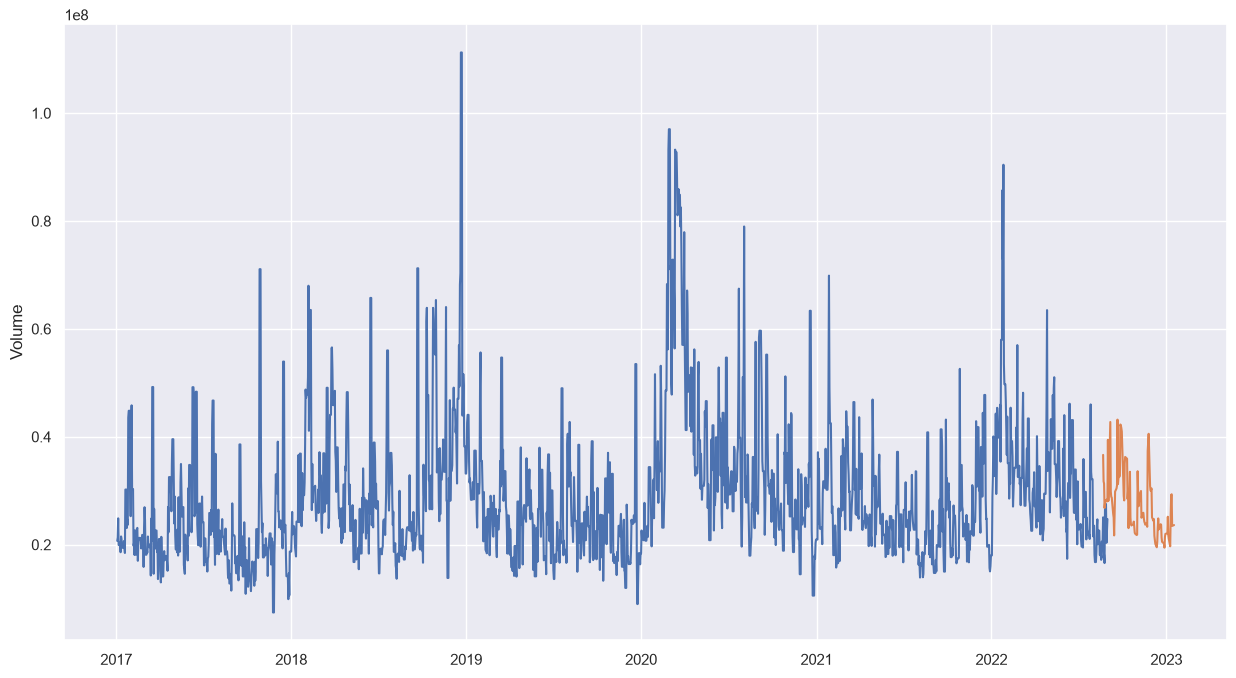

In [81]:
df_forecast.index = predict_period_dates

import seaborn as sns

sns.set(rc = {'figure.figsize':(15,8)})
sns.lineplot( df['Volume'])
sns.lineplot( df_forecast['Volume'])

<Axes: ylabel='Volume'>

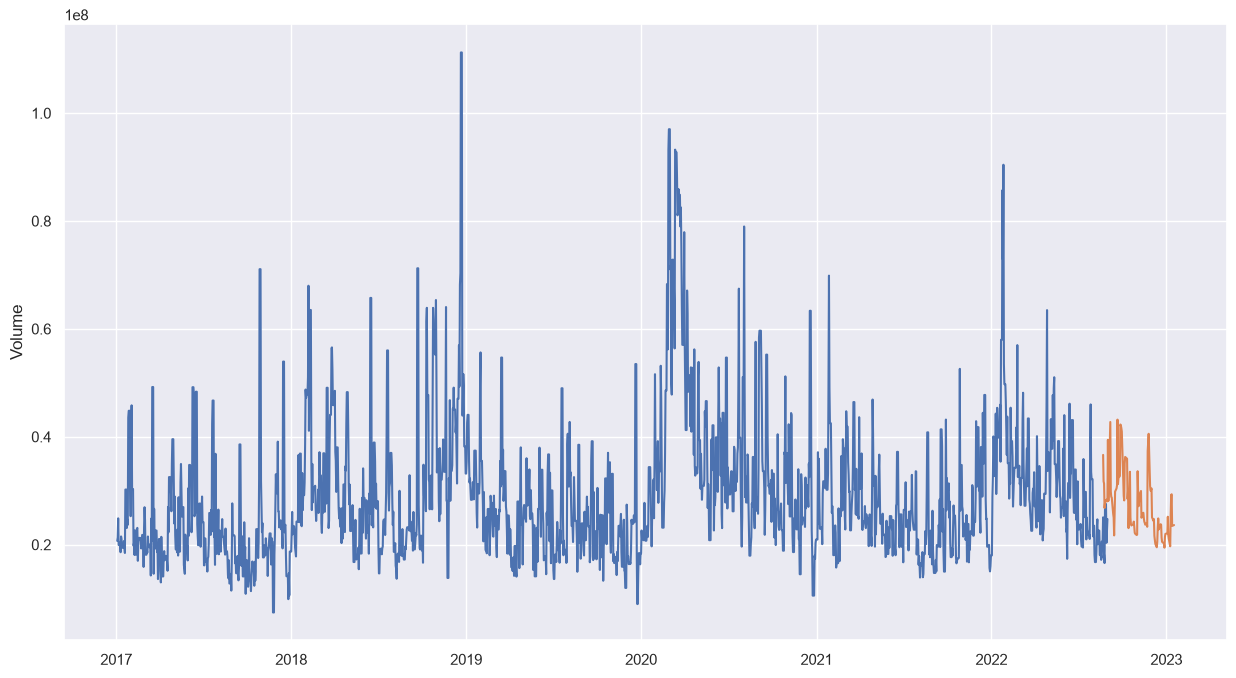

In [82]:
#original=df[['Date','Volume']]
#original['Date']=pd.to_datetime(original['Date'])
#original=original.loc[original['Date']>='2017-1-3']

df_forecast.index = predict_period_dates

import seaborn as sns

sns.set(rc = {'figure.figsize':(15,8)})
sns.lineplot( df['Volume'])
sns.lineplot( df_forecast['Volume'])

#sns.set(rc={'figure.figsize':(15,8)})
#sns.lineplot(original['Date'],original['Volume'])
#sns.lineplot(df_forecast['Date'], df_forecast['Volume'])

# 2- Volume Forecasting Using Stacked LSTM Model

### A standard LSTM processes the sequence in one direction—from the past to the present—to predict the next value. A BiLSTM, on the other hand, processes the sequence in both directions simultaneously: forward (past to future) and backward (future to past). This allows the model to capture dependencies from both directions, which can be very powerful for certain patterns.